***MODEL EVALUATION***

## Load saved evaluation results

Run notebook 2 from beginning to end before running this notebook. It saves accuracy, precision, recall, and F1-score for each experiment on the validation and test sets. Scores range from 0 to 1; precision, recall, and F1 treat obese (`1`) as the positive class.


In [10]:
from pathlib import Path
import pandas as pd

results_path = Path("../results/model_comparison.csv")
if not results_path.exists():
    raise FileNotFoundError(
        "Run notebook 2 from beginning to end first to create "
        "results/model_comparison.csv."
    )

results_df = pd.read_csv(results_path)
results_df


,Experiment,Dataset,Accuracy,Precision,Recall,F1
0,Logistic Regression - All Features,Validation,1.000000,1.000000,1.000000,1.000000
1,Logistic Regression - All Features,Test,0.997183,1.000000,0.993939,0.996960
2,Logistic Regression - Height and Weight,Validation,1.000000,1.000000,1.000000,1.000000
3,Logistic Regression - Height and Weight,Test,0.991549,0.993902,0.987879,0.990881
4,Logistic Regression - Without Height and Weight,Validation,0.767606,0.711538,0.840909,0.770833
5,Logistic Regression - Without Height and Weight,Test,0.774648,0.724868,0.830303,0.774011
6,Tuned SVM - Without Height and Weight,Validation,0.936620,0.925373,0.939394,0.932331
7,Tuned SVM - Without Height and Weight,Test,0.926761,0.911243,0.933333,0.922156
8,Logistic Regression - Without Weight,Validation,0.774648,0.720779,0.840909,0.776224
9,Logistic Regression - Without Weight,Test,0.788732,0.739362,0.842424,0.787535


## Compare validation accuracy

Comparing validation accuracy across all four experiments. We will interpret their scores alongside the features available to each model.


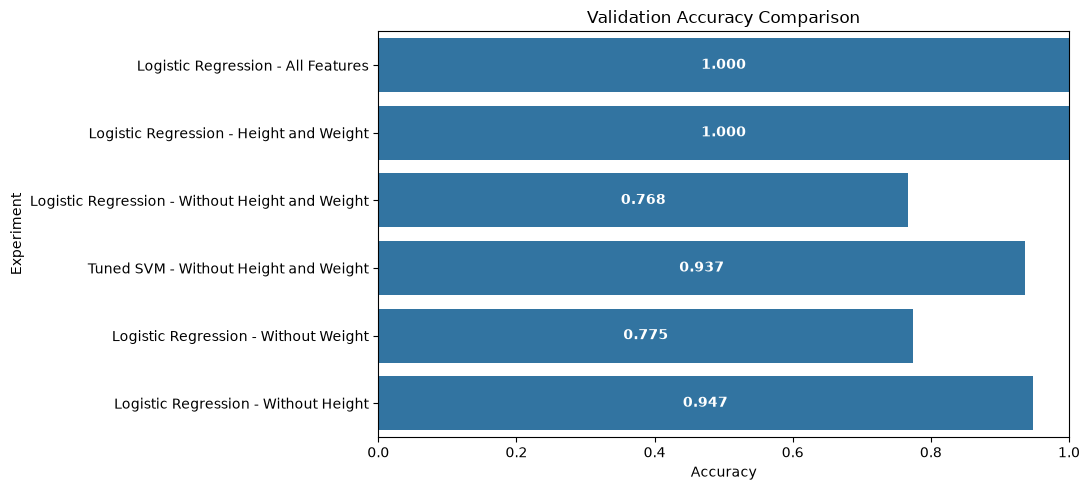

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

validation_results = results_df.loc[results_df["Dataset"] == "Validation"]

plt.figure(figsize=(11, 5))
ax = sns.barplot(
    data=validation_results,
    x="Accuracy",
    y="Experiment"
)

for container in ax.containers:
    ax.bar_label(
        container, fmt="%.3f", label_type="center",
        color="white", fontweight="bold"
    )

plt.xlim(0, 1)
plt.title("Validation Accuracy Comparison")
plt.tight_layout()
plt.show()


We can see above that the models that included height and weight scored perfectly through validation. This was expected, as these features alone are used to calculate BMI which directly defines obesity. The regression model that did not have access to these features scored poorer by comparison with a 77% accuracy. When this model was tuned with the SVM pipeline, its accuracy on the validation set increased to 94%.

After looking at the evaluation, we noticed that we did not train models to reflect using either height or weight along with the rest of the feature set. The last two models displayed reflect those newer models. Interestingly, the model without weight only performs marginally better than the one without either height or weight, suggesting that the model did not weigh height much. However, the model that used only weight with the rest of the feature set had a very high validation accuracy, even beating the tuned model that did not feature height nor weight. This suggests that weight alone may be an important indicator of obesity risk given this data set.